# Cofactor Sensitivity Analysis — COX-2 (5IKQ) with and without the heme cofactor (Reviewer Response, Remaining Issue 4)

**Reviewer comment:** *Removal of COX-2 heme and aldose-reductase NADP+ needs justification. Removing these cofactors may affect the binding environment. Provide structural/literature justification and, if possible, a sensitivity analysis with and without the cofactors.*

This notebook replaces the per-plant docking notebooks for this target for the purpose of the revision: it docks **all compounds from all five plants** against COX-2 (PDB 5IKQ) under **two receptor conditions that differ only in the cofactor**:

| Condition | Receptor |
|---|---|
| `without` | your original prepared receptor `5IKQ_clean_H.pdbqt` (protein only, as in the manuscript) |
| `with` | the same receptor **plus** the crystallographic cofactor (cobalt-protoporphyrin IX (COH), the heme analogue in this crystal; both chains) |

Everything else is identical in both conditions: the same ligand files, docking box (native ligand meclofenamic acid, JMS, chain A, extended 5 Å, as in the original notebooks), AutoDock Vina, seed 42, exhaustiveness 10.

| Step | Content |
|---|---|
| 1 | Configuration and compound list (with SMILES corrections) |
| 2 | SMILES check (molecular formulas) |
| 3 | Receptors: without cofactor (original) and with cofactor |
| 4 | Docking box and **structural check**: distance between cofactor and binding site |
| 5 | Helper functions (ligand preparation, docking, symmetry-corrected RMSD) |
| 6 | **Redocking validation** of the native ligand in both conditions (fixed RMSD calculation) |
| 7 | Docking of all compounds in both conditions |
| 8 | **Sensitivity results**: Δscore, Spearman ρ, top-5 overlap, poses occupying the cofactor site |
| 9 | Figure |
| 10 | Save results and auto-filled text for the manuscript and response letter |

**Two problems found in the original notebooks are corrected here** (details in Steps 1 and 6):
1. Several SMILES did not correspond to the named compound.
2. The redocking RMSD in the original notebooks was never computed (`RMSD = None` for every pose → "FAIL"), because RDKit could not match the PyMOL-exported mol2 to the docked SDF. Step 6 uses a symmetry-corrected, element-matched RMSD that does not depend on bond perception.

## Step 1 — Configuration and Compound List

In [1]:
import os, re, sys, json, time, shutil, subprocess, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import spearmanr
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem.rdMolDescriptors import CalcMolFormula
from openbabel import openbabel as ob
from openbabel import pybel
from vina import Vina
warnings.filterwarnings("ignore")
ob.obErrorLog.SetOutputLevel(0)

# ---- Paths (same folder as the original docking notebooks) ----
DOCKING_DIR = "/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/"
PREP_LIG_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand"
OUT_DIR = os.path.join(DOCKING_DIR, "cofactor_sensitivity", "5IKQ")
os.makedirs(OUT_DIR, exist_ok=True)

# ---- Target ----
PDB            = "5IKQ"
TARGET_NAME    = "COX-2"
NATIVE_LIG_RESN = "JMS"          # co-crystallized inhibitor (meclofenamic acid, JMS, chain A)
NATIVE_LIG_CHAIN = "A"
COFACTOR_RESN  = "COH"              # cobalt-protoporphyrin IX (COH), the heme analogue in this crystal; both chains
COFACTOR_CHAINS = ["A", "B"]        # cofactor copies kept in the "with" receptor
METAL_RENAME   = {"CO": "Fe"}       # element substitutions in the cofactor (see Step 3 note)
COFACTOR_TEXT  = "In this crystal structure the heme is present as Co(III)-protoporphyrin IX (COH), which occupies the peroxidase site; for the sensitivity analysis it was retained with Co replaced by Fe to represent the native heme."

RECEPTOR_WITHOUT_PDBQT = os.path.join(DOCKING_DIR, f"5IKQ_clean_H.pdbqt")   # original receptor
NATIVE_LIG_MOL2        = os.path.join(DOCKING_DIR, f"5IKQ_native_lig.mol2")  # original native ligand

# ---- Docking protocol: identical to the original notebooks ----
VINA_SEED, EXHAUSTIVENESS, N_POSES, BOX_EXTENDING = 42, 10, 10, 5.0
SPECIAL = {"Stigmasterol": {"box_pad": 8.0, "exhaustiveness": 32}}   # per-compound overrides used in the original notebooks

# ---- Compounds of all five plants (SMILES corrected where the original was wrong) ----
COMPOUNDS = {
    # name:               (plant, SMILES)
    "Carvone":            ("Mentha spicata",         "CC1=CCC(CC1=O)C(=C)C"),
    "Limonene":           ("Mentha spicata",         "CC1=CCC(CC1)C(=C)C"),
    "cis_Dihydrocarvone": ("Mentha spicata",         "CC1CCC(CC1=O)C(=C)C"),
    "beta_Caryophyllene": ("Mentha spicata",         "CC1=CCCC(=C)C2CC(C2CC1)(C)C"),
    "Linalyl_acetate":    ("Lavandula angustifolia", "CC(=CCCC(C)(C=C)OC(C)=O)C"),
    "Linalool":           ("Lavandula angustifolia", "OC(CC=C)(C)CCC=C(C)C"),
    "Hexyl_butyrate":     ("Lavandula angustifolia", "CCCCCCOC(=O)CCC"),
    "Lavandulyl_acetate": ("Lavandula angustifolia", "CC(=CCC(COC(C)=O)C(C)=C)C"),
    "Cineole_1_8":        ("Lavandula dentata",      "CC1(C2CCC(O1)(CC2)C)C"),
    "cis_Verbenol":       ("Lavandula dentata",      "CC1=CC(C2CC1C2(C)C)O"),
    "p_Cymen_8_ol":       ("Lavandula dentata",      "CC1=CC=C(C=C1)C(C)(C)O"),
    "Myrtenal":           ("Lavandula dentata",      "CC1(C)C2CC=C(C=O)C1C2"),
    "Fenchone":           ("Lavandula stoechas",     "CC1(C)C2CCC(C)(C2)C1=O"),
    "Camphor":            ("Lavandula stoechas",     "CC1(C)C2CCC1(C)C(=O)C2"),
    "p_Cymene":           ("Lavandula stoechas",     "Cc1ccc(C(C)C)cc1"),
    "alpha_Pinene":       ("Lavandula stoechas",     "CC1=CCC2CC1C2(C)C"),
    "Chrysoeriol":        ("Lamium amplexicaule",    "COC1=C(C=CC(=C1)C2=CC(=O)C3=C(C=C(C=C3O2)O)O)O"),
    "Stigmasterol":       ("Lamium amplexicaule",    "CC[C@H](/C=C/[C@@H](C)[C@H]1CC[C@@H]2[C@@]1(CC[C@H]3[C@H]2CC=C4[C@@]3(CC[C@@H](C4)O)C)C)C(C)C"),
}

# SMILES used in the ORIGINAL 5IKQ notebooks, where they differ from the corrected ones above
ORIGINAL_SMILES = {
    "Carvone":            "CC1=CC(=O)C(=CC1)C(=C)C",        # C10H12O, not carvone
    "Limonene":           "CC1=CCC(=CC1)C(C)=C",            # C10H14, not limonene
    "cis_Dihydrocarvone": "CC1CC(=O)C(=CC1)C(C)C",          # isomer, not dihydrocarvone
    "Lavandulyl_acetate": "CC(=CCC(C)(C=C)COC(C)=O)C",      # isomer, not lavandulyl acetate
    "Fenchone":           "CC1(C)C2CCC1(C)C(=O)C2",          # this is camphor
    "Camphor":            "CC1(C)C2CCC1(C)CC(=O)C2",         # C11H18O, extra carbon
}

# Scores reported in the manuscript / original notebooks for this target (kcal/mol)
ORIGINAL_SCORES = {
    "Carvone": -6.546, "Limonene": -6.612, "cis_Dihydrocarvone": -6.352, "beta_Caryophyllene": -6.743,
    "Linalyl_acetate": -5.711, "Linalool": -5.684, "Hexyl_butyrate": -4.963, "Lavandulyl_acetate": -5.672,
    "Cineole_1_8": -5.738, "cis_Verbenol": -5.696, "p_Cymen_8_ol": -6.687, "Myrtenal": -5.980,
    "Fenchone": -5.174, "Camphor": -5.671, "p_Cymene": -5.883, "alpha_Pinene": -5.699,
    "Chrysoeriol": -8.802, "Stigmasterol": -3.689,
}

print(f"Target: COX-2 (5IKQ) | cofactor {COFACTOR_RESN} | native ligand {NATIVE_LIG_RESN}")
print(f"{len(COMPOUNDS)} compounds from {len({p for p, _ in COMPOUNDS.values()})} plants | output: {OUT_DIR}")

Target: COX-2 (5IKQ) | cofactor COH | native ligand JMS
18 compounds from 5 plants | output: /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/cofactor_sensitivity/5IKQ


## Step 2 — SMILES Check

Compares the corrected SMILES with those used in the original notebooks. Compounds marked **CHANGED** were docked with a structure that was not the named compound, so their original scores (in this target and in every other target docked with the same SMILES) must be replaced.

In [2]:
canon = lambda s: Chem.MolToSmiles(Chem.MolFromSmiles(s), isomericSmiles=False)
rows = []
for name, (plant, smi) in COMPOUNDS.items():
    m = Chem.MolFromSmiles(smi)
    assert m is not None, f"Invalid SMILES for {name}"
    old = ORIGINAL_SMILES.get(name)
    changed = old is not None and canon(old) != canon(smi)
    rows.append({"Compound": name, "Plant": plant, "Formula": CalcMolFormula(m),
                 "Original_formula": CalcMolFormula(Chem.MolFromSmiles(old)) if old else "",
                 "Status": "CHANGED (original SMILES wrong)" if changed else "ok"})
smiles_check = pd.DataFrame(rows)
print(smiles_check.to_string(index=False))
smiles_check.to_csv(os.path.join(OUT_DIR, f"{PDB}_smiles_check.csv"), index=False)
CHANGED = smiles_check.loc[smiles_check.Status != "ok", "Compound"].tolist()
print(f"\nCompounds whose original SMILES was wrong: {CHANGED or 'none'}")

          Compound                  Plant  Formula Original_formula                          Status
           Carvone         Mentha spicata  C10H14O          C10H12O CHANGED (original SMILES wrong)
          Limonene         Mentha spicata   C10H16           C10H14 CHANGED (original SMILES wrong)
cis_Dihydrocarvone         Mentha spicata  C10H16O          C10H16O CHANGED (original SMILES wrong)
beta_Caryophyllene         Mentha spicata   C15H24                                               ok
   Linalyl_acetate Lavandula angustifolia C12H20O2                                               ok
          Linalool Lavandula angustifolia  C11H20O                                               ok
    Hexyl_butyrate Lavandula angustifolia C10H20O2                                               ok
Lavandulyl_acetate Lavandula angustifolia C12H20O2         C12H20O2 CHANGED (original SMILES wrong)
       Cineole_1_8      Lavandula dentata  C10H18O                                               ok


## Step 3 — Receptors Without and With the Cofactor

* **without** = your original `5IKQ_clean_H.pdbqt`, unchanged. If it is missing, a fallback receptor is built with OpenBabel (a warning is printed; results then differ slightly from the manuscript).
* **with** = the same file plus the cofactor extracted from the same biological assembly (`5IKQ.pdb1`, model 1), protonated at pH 7.4 with OpenBabel and converted to rigid PDBQT atoms.

**Note on the metal:** in 5IKQ the heme is crystallised as **Co(III)-protoporphyrin IX (residue COH)**, a common substitute for Fe-heme in COX crystallography. Because the reviewer asks about the *heme*, Co is replaced by Fe (`METAL_RENAME`) so the retained cofactor represents the native heme. Set `METAL_RENAME = {}` to keep cobalt instead.

In [3]:
PDB1_PATH = os.path.join(OUT_DIR, f"{PDB}.pdb1")
if not os.path.exists(PDB1_PATH):
    print(f"Downloading {PDB}.pdb1 from RCSB ...")
    urllib.request.urlretrieve(f"https://files.rcsb.org/download/{PDB}.pdb1", PDB1_PATH)

def model1_lines(path):
    out = []
    for line in open(path):
        if line.startswith("ENDMDL"):
            break
        if line.startswith(("ATOM", "HETATM")):
            out.append(line)
    return out

PDB1_LINES = model1_lines(PDB1_PATH)

# ---- receptor WITHOUT cofactor (the original one) ----
if os.path.exists(RECEPTOR_WITHOUT_PDBQT):
    print(f"Using ORIGINAL receptor: {RECEPTOR_WITHOUT_PDBQT}")
else:
    print(f"WARNING: {RECEPTOR_WITHOUT_PDBQT} not found -- building a fallback receptor with OpenBabel.")
    RECEPTOR_WITHOUT_PDBQT = os.path.join(OUT_DIR, f"{PDB}_protein_fallback.pdbqt")
    prot_pdb = os.path.join(OUT_DIR, f"{PDB}_protein_only.pdb")
    with open(prot_pdb, "w") as f:
        f.writelines(l for l in PDB1_LINES if l.startswith("ATOM"))
    m = next(pybel.readfile("pdb", prot_pdb))
    m.OBMol.AddHydrogens(False, True, 7.4)
    m.write("pdbqt", RECEPTOR_WITHOUT_PDBQT, overwrite=True, opt={"r": None})

# ---- native ligand mol2 (original, or extracted here if missing) ----
if not os.path.exists(NATIVE_LIG_MOL2):
    print(f"WARNING: {NATIVE_LIG_MOL2} not found -- extracting {NATIVE_LIG_RESN} chain {NATIVE_LIG_CHAIN} from {PDB}.pdb1")
    NATIVE_LIG_MOL2 = os.path.join(OUT_DIR, f"{PDB}_native_lig.mol2")
    tmp = os.path.join(OUT_DIR, "_natlig.pdb")
    with open(tmp, "w") as f:
        f.writelines(l for l in PDB1_LINES if l[17:20].strip() == NATIVE_LIG_RESN and l[21] == NATIVE_LIG_CHAIN)
    next(pybel.readfile("pdb", tmp)).write("mol2", NATIVE_LIG_MOL2, overwrite=True)

# ---- cofactor: extract, protonate, convert ----
cof_lines = [l for l in PDB1_LINES if l.startswith("HETATM") and l[17:20].strip() == COFACTOR_RESN
             and l[21] in COFACTOR_CHAINS]
assert cof_lines, f"No {COFACTOR_RESN} found in {PDB}.pdb1 model 1"
cof_pdb = os.path.join(OUT_DIR, f"{PDB}_{COFACTOR_RESN}.pdb")
with open(cof_pdb, "w") as f:
    for l in cof_lines:
        el = l[76:78].strip()
        if el in METAL_RENAME:
            new = METAL_RENAME[el]
            l = l[:12] + f"{new.upper():>4}"[:4] + l[16:76] + f"{new.upper():>2}" + l[78:]
        f.write(l)
    f.write("END\n")
copies = sorted({(l[21], l[22:26].strip()) for l in cof_lines})
cof_heavy = [l for l in cof_lines if l[76:78].strip() != "H"]
print(f"Cofactor {COFACTOR_RESN}: {len(cof_heavy)} heavy atoms ({len(cof_lines)} incl. crystallographic H), "
      f"copies (chain, resi): {copies}")
if METAL_RENAME:
    print(f"Metal substitution applied: {METAL_RENAME}")

cof_pdbqt = os.path.join(OUT_DIR, f"{PDB}_{COFACTOR_RESN}.pdbqt")
cof_mols = list(pybel.readfile("pdb", cof_pdb))
cof_lines_q = []
for k, cm in enumerate(cof_mols):
    cm.OBMol.AddHydrogens(False, True, 7.4)
    part = os.path.join(OUT_DIR, f"_cof_{k}.pdbqt")
    cm.write("pdbqt", part, overwrite=True, opt={"r": None})
    cof_lines_q += [l for l in open(part) if l.startswith(("ATOM", "HETATM"))]
with open(cof_pdbqt, "w") as f:
    f.writelines(cof_lines_q)

# ---- receptor WITH cofactor = original receptor + cofactor atoms ----
RECEPTOR_WITH_PDBQT = os.path.join(OUT_DIR, f"{PDB}_clean_H_with{COFACTOR_RESN}.pdbqt")
rec_lines = [l for l in open(RECEPTOR_WITHOUT_PDBQT) if l.startswith(("ATOM", "HETATM"))]
with open(RECEPTOR_WITH_PDBQT, "w") as f:
    f.writelines(rec_lines + cof_lines_q)
    f.write("END\n")

types = pd.Series([l[77:79].strip() for l in cof_lines_q]).value_counts().to_dict()
print(f"Receptor without cofactor: {len(rec_lines):,} atoms")
print(f"Receptor with cofactor   : {len(rec_lines) + len(cof_lines_q):,} atoms "
      f"(+{len(cof_lines_q)} cofactor atoms; AutoDock types {types})")
print(f"Saved: {RECEPTOR_WITH_PDBQT}")
RECEPTORS = {"without": RECEPTOR_WITHOUT_PDBQT, "with": RECEPTOR_WITH_PDBQT}

Using ORIGINAL receptor: /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/5IKQ_clean_H.pdbqt
Cofactor COH: 86 heavy atoms (146 incl. crystallographic H), copies (chain, resi): [('A', '609'), ('B', '601')]
Metal substitution applied: {'CO': 'Fe'}
Receptor without cofactor: 10,842 atoms
Receptor with cofactor   : 10,928 atoms (+86 cofactor atoms; AutoDock types {'C': 52, 'A': 16, 'N': 8, 'OA': 8, 'Fe': 2})
Saved: /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/cofactor_sensitivity/5IKQ/5IKQ_clean_H_withCOH.pdbqt


## Step 4 — Docking Box and Structural Check

The box is computed exactly as Jupyter Dock's `getbox(selection='natlig', extending=5.0)`: centre = midpoint of the native-ligand extent, size = extent + 2 × 5 Å.

The distance between the cofactor and the native ligand is the **structural justification** asked for by the reviewer:
* contact (< 4.5 Å): the cofactor lines the binding site → it should be kept;
* 4.5–8 Å: near the site → sensitivity analysis decides;
* > 8 Å and outside the box: remote → removal is structurally justified.

In [4]:
def heavy_coords_from_mol2(path):
    m = next(pybel.readfile("mol2", path))
    xyz = np.array([a.coords for a in m.atoms if a.atomicnum > 1])
    el = [ob.GetSymbol(a.atomicnum) for a in m.atoms if a.atomicnum > 1]
    return xyz, el

nat_xyz, nat_el = heavy_coords_from_mol2(NATIVE_LIG_MOL2)
lo, hi = nat_xyz.min(0) - BOX_EXTENDING, nat_xyz.max(0) + BOX_EXTENDING
BOX_CENTER = ((lo + hi) / 2).round(3).tolist()
BOX_SIZE   = (hi - lo).round(3).tolist()
print(f"Native ligand: {len(nat_xyz)} heavy atoms")
print(f"Box centre {BOX_CENTER} | size {BOX_SIZE}")

cof_xyz = np.array([[float(l[30:38]), float(l[38:46]), float(l[46:54])] for l in cof_heavy])
d = np.linalg.norm(nat_xyz[:, None] - cof_xyz[None], axis=2)
in_box = np.all((cof_xyz >= lo) & (cof_xyz <= hi), axis=1)
STRUCT = {"min_dist_native_ligand_to_cofactor_A": round(float(d.min()), 2),
          "cofactor_atoms_within_4A_of_native_ligand": int((d.min(0) < 4.0).sum()),
          "cofactor_atoms_inside_docking_box": int(in_box.sum()),
          "cofactor_heavy_atoms_total": len(cof_xyz)}
for k, v in STRUCT.items():
    print(f"  {k:<45}: {v}")
STRUCT["verdict"] = ("contact: cofactor lines the binding site -> keep it" if STRUCT["min_dist_native_ligand_to_cofactor_A"] < 4.5 else
                     "near the binding site -> rely on the sensitivity analysis" if STRUCT["min_dist_native_ligand_to_cofactor_A"] < 8 or in_box.any() else
                     "remote from the binding site -> removal structurally justified")
print(f"Verdict: {STRUCT['verdict']}")

Native ligand: 19 heavy atoms
Box centre [22.518, 51.524, 17.635] | size [16.493, 17.13, 15.424]
  min_dist_native_ligand_to_cofactor_A         : 9.13
  cofactor_atoms_within_4A_of_native_ligand    : 0
  cofactor_atoms_inside_docking_box            : 0
  cofactor_heavy_atoms_total                   : 86
Verdict: remote from the binding site -> removal structurally justified


## Step 5 — Helper Functions

* **Ligand preparation** is the same as in the 2FZD notebooks (the most careful version in the project): 20 ETKDGv3 conformers → MMFF94 minimisation → lowest-energy conformer → `prepare_ligand` (OpenBabel fallback). The **same** ligand file is used in both receptor conditions.
* **RMSD** is symmetry-corrected and element-matched (Hungarian assignment per element on heavy atoms, no re-superposition), so it works even when bond orders differ between the crystal mol2 and the docked pose.

In [5]:
LIG_DIR = os.path.join(OUT_DIR, "ligands"); os.makedirs(LIG_DIR, exist_ok=True)
AD2EL = {"A": "C", "C": "C", "N": "N", "NA": "N", "NS": "N", "OA": "O", "OS": "O", "O": "O",
         "S": "S", "SA": "S", "P": "P", "F": "F", "Cl": "Cl", "CL": "Cl", "Br": "Br", "BR": "Br",
         "I": "I", "H": "H", "HD": "H", "HS": "H"}

def obabel_to_pdbqt(src, fmt, dst, add_h=False):
    m = next(pybel.readfile(fmt, src))
    if add_h:
        m.OBMol.AddHydrogens(False, True, 7.4)
    m.write("pdbqt", dst, overwrite=True)
    return dst

def prepare_ligand_from_smiles(name, smiles, n_confs=20):
    pdbqt = os.path.join(LIG_DIR, f"{name}.pdbqt")
    if os.path.exists(pdbqt) and os.path.getsize(pdbqt) > 0:
        return pdbqt                                       # identical file reused in both conditions
    m = Chem.AddHs(Chem.MolFromSmiles(smiles))
    p = AllChem.ETKDGv3(); p.randomSeed = 42
    cids = list(AllChem.EmbedMultipleConfs(m, numConfs=n_confs, params=p))
    props = AllChem.MMFFGetMoleculeProperties(m)
    energies = []
    for cid in cids:
        ff = AllChem.MMFFGetMoleculeForceField(m, props, confId=cid) if props else AllChem.UFFGetMoleculeForceField(m, confId=cid)
        ff.Minimize(maxIts=2000); energies.append((ff.CalcEnergy(), cid))
    e, best = min(energies)
    pdb = os.path.join(LIG_DIR, f"{name}.pdb")
    Chem.MolToPDBFile(m, pdb, confId=best)
    if os.path.exists(PREP_LIG_BIN):
        subprocess.run([PREP_LIG_BIN, "-v", "-l", pdb, "-o", pdbqt], capture_output=True, text=True,
                       cwd=LIG_DIR)
    if not os.path.exists(pdbqt) or os.path.getsize(pdbqt) == 0:
        obabel_to_pdbqt(pdb, "pdb", pdbqt)
    print(f"    prepared {name}: {len(cids)} conformers, lowest MMFF energy {e:.2f} (conf {best})")
    return pdbqt

def read_poses(pdbqt_path):
    """Heavy-atom coordinates and elements of every pose in a Vina output file."""
    poses, cur = [], []
    for line in open(pdbqt_path):
        if line.startswith("MODEL"):
            cur = []
        elif line.startswith(("ATOM", "HETATM")):
            el = AD2EL.get(line[77:79].strip(), line[77:79].strip())
            if el != "H":
                cur.append((el, float(line[30:38]), float(line[38:46]), float(line[46:54])))
        elif line.startswith("ENDMDL"):
            poses.append(cur)
    return [(np.array([c[1:] for c in p]), [c[0] for c in p]) for p in poses]

def sym_rmsd(xyz_a, el_a, xyz_b, el_b):
    """Symmetry-corrected RMSD: optimal one-to-one matching of same-element heavy atoms."""
    if sorted(el_a) != sorted(el_b):
        return np.nan
    sq = 0.0
    for e in set(el_a):
        ia = [i for i, x in enumerate(el_a) if x == e]; ib = [i for i, x in enumerate(el_b) if x == e]
        dm = ((xyz_a[ia][:, None] - xyz_b[ib][None]) ** 2).sum(-1)
        r, c = linear_sum_assignment(dm); sq += dm[r, c].sum()
    return float(np.sqrt(sq / len(el_a)))

def dock(lig_pdbqt, receptor, tag, box_size=None, exhaustiveness=None):
    v = Vina(sf_name="vina", seed=VINA_SEED, verbosity=0)
    v.set_receptor(receptor)
    v.set_ligand_from_file(lig_pdbqt)
    v.compute_vina_maps(center=BOX_CENTER, box_size=box_size or BOX_SIZE)
    v.dock(exhaustiveness=exhaustiveness or EXHAUSTIVENESS, n_poses=N_POSES)
    out = os.path.join(OUT_DIR, f"{tag}_vina_out.pdbqt")
    v.write_poses(out, n_poses=N_POSES, overwrite=True)
    return v.energies(n_poses=N_POSES)[:, 0], out

print("Helpers ready.")

Helpers ready.


## Step 6 — Redocking Validation in Both Conditions

The crystallographic meclofenamic acid, JMS, chain A is protonated at pH 7.4, redocked into the same box, and every pose is compared with the crystal pose. Criterion: best-scoring pose RMSD < 2.0 Å.

In [6]:
nat_pdbqt = obabel_to_pdbqt(NATIVE_LIG_MOL2, "mol2", os.path.join(LIG_DIR, f"{PDB}_native_{NATIVE_LIG_RESN}.pdbqt"), add_h=True)
redock_rows = []
for cond, rec in RECEPTORS.items():
    t0 = time.time()
    print(f"[redock] {NATIVE_LIG_RESN} vs {PDB} {cond} {COFACTOR_RESN} ...", flush=True)
    scores, out = dock(nat_pdbqt, rec, f"redock_{NATIVE_LIG_RESN}_{cond}")
    for i, (xyz, el) in enumerate(read_poses(out)):
        redock_rows.append({"Condition": cond, "Pose": i + 1, "Vina_score": round(float(scores[i]), 3),
                            "RMSD_A": round(sym_rmsd(xyz, el, nat_xyz, nat_el), 3)})
    best = [r for r in redock_rows if r["Condition"] == cond][0]
    min_rmsd = min(r["RMSD_A"] for r in redock_rows if r["Condition"] == cond)
    print(f"    best pose: score {best['Vina_score']} kcal/mol, RMSD {best['RMSD_A']} A -> "
          f"{'PASS' if best['RMSD_A'] < 2.0 else 'FAIL'} | lowest RMSD among {N_POSES} poses: {min_rmsd} A "
          f"({time.time() - t0:.0f}s)")
redock_df = pd.DataFrame(redock_rows)
redock_df.to_csv(os.path.join(OUT_DIR, f"{PDB}_redocking_with_without_{COFACTOR_RESN}.csv"), index=False)
REDOCK = {c: {"best_score": float(g.iloc[0].Vina_score), "best_pose_rmsd": float(g.iloc[0].RMSD_A),
              "min_rmsd_all_poses": float(g.RMSD_A.min()), "pass": bool(g.iloc[0].RMSD_A < 2.0)}
          for c, g in redock_df.groupby("Condition")}
print(pd.DataFrame(REDOCK).T.to_string())

[redock] JMS vs 5IKQ without COH ...
    best pose: score -9.057 kcal/mol, RMSD 0.59 A -> PASS | lowest RMSD among 10 poses: 0.59 A (3s)
[redock] JMS vs 5IKQ with COH ...


    best pose: score -9.062 kcal/mol, RMSD 0.58 A -> PASS | lowest RMSD among 10 poses: 0.58 A (4s)
        best_score best_pose_rmsd min_rmsd_all_poses  pass
with        -9.062           0.58               0.58  True
without     -9.057           0.59               0.59  True


## Step 7 — Dock All Compounds in Both Conditions

Same ligand file, box, seed and exhaustiveness in both conditions. As in the original `5IKQ_LamiumAmplexicaule_FULL_v3` notebook, Stigmasterol uses the widened box (+8 Å) and exhaustiveness 32, in **both** conditions.

In [7]:
results = []
names = list(COMPOUNDS)
T0 = time.time()
for k, name in enumerate(names, 1):
    plant, smi = COMPOUNDS[name]
    print(f"[{k}/{len(names)}] {name} ({plant})", flush=True)
    lig = prepare_ligand_from_smiles(name, smi)
    sp = SPECIAL.get(name, {})
    box = [s + sp.get("box_pad", 0.0) for s in BOX_SIZE]
    for cond, rec in RECEPTORS.items():
        t0 = time.time()
        scores, out = dock(lig, rec, f"{name}_{PDB}_{cond}_{COFACTOR_RESN}", box_size=box,
                           exhaustiveness=sp.get("exhaustiveness", EXHAUSTIVENESS))
        xyz, el = read_poses(out)[0]
        dmin = float(np.linalg.norm(xyz[:, None] - cof_xyz[None], axis=2).min())
        results.append({"Compound": name, "Plant": plant, "Condition": cond,
                        "Best_score": round(float(scores[0]), 3), "Best_pose_out": out,
                        "Best_pose_min_dist_to_cofactor_A": round(dmin, 2)})
        print(f"    {cond:<7} {COFACTOR_RESN}: {scores[0]:7.3f} kcal/mol | best pose {dmin:5.2f} A from "
              f"cofactor position ({time.time() - t0:.0f}s)", flush=True)
print(f"\nAll docking finished in {(time.time() - T0) / 60:.1f} min")
long_df = pd.DataFrame(results)
long_df.to_csv(os.path.join(OUT_DIR, f"{PDB}_all_poses_summary.csv"), index=False)

[1/18] Carvone (Mentha spicata)
    prepared Carvone: 20 conformers, lowest MMFF energy 26.56 (conf 7)
    without COH:  -6.684 kcal/mol | best pose  9.37 A from cofactor position (2s)


    with    COH:  -6.697 kcal/mol | best pose  9.35 A from cofactor position (2s)
[2/18] Limonene (Mentha spicata)


    prepared Limonene: 20 conformers, lowest MMFF energy 23.66 (conf 11)
    without COH:  -6.517 kcal/mol | best pose  9.37 A from cofactor position (1s)


    with    COH:  -6.455 kcal/mol | best pose  9.46 A from cofactor position (2s)
[3/18] cis_Dihydrocarvone (Mentha spicata)
    prepared cis_Dihydrocarvone: 20 conformers, lowest MMFF energy 18.46 (conf 16)
    without COH:  -6.691 kcal/mol | best pose  9.31 A from cofactor position (2s)


    with    COH:  -6.680 kcal/mol | best pose  9.27 A from cofactor position (2s)
[4/18] beta_Caryophyllene (Mentha spicata)


...

    prepared alpha_Pinene: 20 conformers, lowest MMFF energy 36.81 (conf 18)
    without COH:  -5.895 kcal/mol | best pose 10.35 A from cofactor position (1s)


    with    COH:  -5.901 kcal/mol | best pose 10.38 A from cofactor position (1s)
[17/18] Chrysoeriol (Lamium amplexicaule)


    prepared Chrysoeriol: 20 conformers, lowest MMFF energy 31.92 (conf 3)
    without COH:  -8.816 kcal/mol | best pose  9.31 A from cofactor position (6s)


    with    COH:  -8.813 kcal/mol | best pose  9.32 A from cofactor position (6s)
[18/18] Stigmasterol (Lamium amplexicaule)


    prepared Stigmasterol: 20 conformers, lowest MMFF energy 104.81 (conf 6)
    without COH:  -3.681 kcal/mol | best pose  8.04 A from cofactor position (18s)
    with    COH:  -3.691 kcal/mol | best pose  8.04 A from cofactor position (19s)

All docking finished in 2.3 min


## Step 8 — Sensitivity Results

* **Δ = with − without** (negative = stronger binding with the cofactor present).
* **Spearman ρ** compares the compound rankings in the two conditions; ρ close to 1 means the ranking — and therefore the prioritisation — is robust to the cofactor.
* **Occupies cofactor site**: in the `without` receptor, the best pose comes within 2 Å of where the cofactor atoms normally sit, i.e. the compound docked into space that the real enzyme fills with the cofactor.
* `Original_reported` is the value in the manuscript/original notebooks (wrong-SMILES compounds are flagged).

In [8]:
wide = long_df.pivot(index="Compound", columns="Condition", values="Best_score")[["without", "with"]]
dist = long_df[long_df.Condition == "without"].set_index("Compound")["Best_pose_min_dist_to_cofactor_A"]
sens = wide.rename(columns={"without": f"Without_{COFACTOR_RESN}", "with": f"With_{COFACTOR_RESN}"})
sens.insert(0, "Plant", [COMPOUNDS[c][0] for c in sens.index])
sens.insert(1, "Original_reported", [ORIGINAL_SCORES.get(c, np.nan) for c in sens.index])
sens["Delta_with_minus_without"] = (wide["with"] - wide["without"]).round(3)
sens["Rank_without"] = wide["without"].rank(method="min").astype(int)
sens["Rank_with"] = wide["with"].rank(method="min").astype(int)
sens["Occupies_cofactor_site_without"] = dist < 2.0
sens["SMILES_corrected"] = [c in CHANGED for c in sens.index]
sens = sens.sort_values(f"With_{COFACTOR_RESN}")

rho, p = spearmanr(wide["without"], wide["with"])
top_w = set(wide["without"].nsmallest(5).index); top_c = set(wide["with"].nsmallest(5).index)
SUMMARY = {"target": TARGET_NAME, "pdb": PDB, "cofactor": COFACTOR_RESN, "n_compounds": len(wide),
           "spearman_rho": round(float(rho), 3), "spearman_p": float(p),
           "mean_abs_delta": round(float(sens.Delta_with_minus_without.abs().mean()), 3),
           "max_abs_delta": round(float(sens.Delta_with_minus_without.abs().max()), 3),
           "top5_overlap": f"{len(top_w & top_c)}/5",
           "top5_without": sorted(top_w), "top5_with": sorted(top_c),
           "n_occupying_cofactor_site_without": int(sens.Occupies_cofactor_site_without.sum()),
           "structural_check": STRUCT, "redocking": REDOCK}
pd.set_option("display.width", 200)
print(sens.drop(columns=[]).to_string())
print(f"\nSpearman rho (without vs with): {rho:.3f} (p = {p:.2e})")
print(f"Mean |delta| = {SUMMARY['mean_abs_delta']} kcal/mol | max |delta| = {SUMMARY['max_abs_delta']} kcal/mol")
print(f"Top-5 overlap: {SUMMARY['top5_overlap']} | without: {sorted(top_w)} | with: {sorted(top_c)}")
print(f"Compounds whose 'without' pose occupies the cofactor site: "
      f"{sens.index[sens.Occupies_cofactor_site_without].tolist() or 'none'}")

Condition                            Plant  Original_reported  Without_COH  With_COH  Delta_with_minus_without  Rank_without  Rank_with  Occupies_cofactor_site_without  SMILES_corrected
Compound                                                                                                                                                                                 
Chrysoeriol            Lamium amplexicaule             -8.802       -8.816    -8.813                     0.003             1          1                           False             False
p_Cymen_8_ol             Lavandula dentata             -6.687       -6.684    -6.699                    -0.015             3          2                           False             False
Carvone                     Mentha spicata             -6.546       -6.684    -6.697                    -0.013             3          3                           False              True
cis_Dihydrocarvone          Mentha spicata             -6.352       -6

## Step 9 — Figure

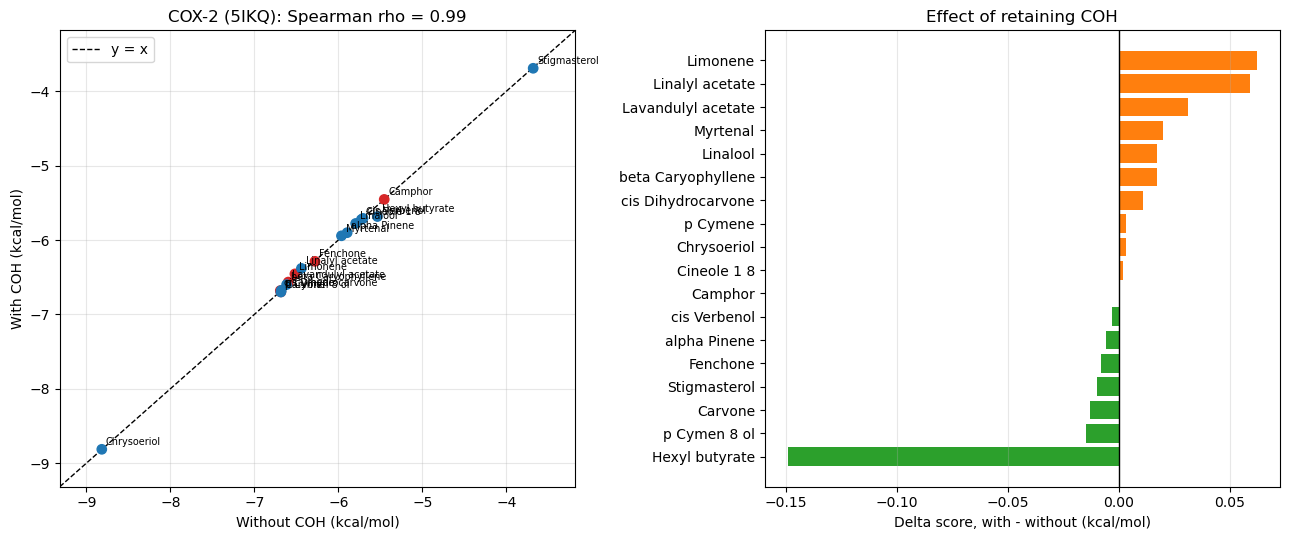

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
ax = axes[0]
x, y = wide["without"], wide["with"]
ax.scatter(x, y, s=45, c=["#d62728" if c in CHANGED else "#1f77b4" for c in wide.index], zorder=3)
for c in wide.index:
    ax.annotate(c.replace("_", " "), (x[c], y[c]), fontsize=7, xytext=(3, 3), textcoords="offset points")
lims = [min(x.min(), y.min()) - 0.5, max(x.max(), y.max()) + 0.5]
ax.plot(lims, lims, "k--", lw=1, label="y = x")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel(f"Without {COFACTOR_RESN} (kcal/mol)"); ax.set_ylabel(f"With {COFACTOR_RESN} (kcal/mol)")
ax.set_title(f"{TARGET_NAME} ({PDB}): Spearman rho = {rho:.2f}"); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
s = sens.sort_values("Delta_with_minus_without")
ax.barh([c.replace("_", " ") for c in s.index], s.Delta_with_minus_without,
        color=["#2ca02c" if v < 0 else "#ff7f0e" for v in s.Delta_with_minus_without])
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Delta score, with - without (kcal/mol)")
ax.set_title(f"Effect of retaining {COFACTOR_RESN}"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(OUT_DIR, f"{PDB}_cofactor_sensitivity.{ext}"), dpi=300, bbox_inches="tight")
plt.show()

## Step 10 — Save Results and Auto-Filled Text

The text below is filled with this run's numbers. Paste it into the Methods (p. 29) and the response letter, then adjust the wording.

In [10]:
sens.to_csv(os.path.join(OUT_DIR, f"{PDB}_cofactor_sensitivity_table.csv"))
with open(os.path.join(OUT_DIR, f"{PDB}_cofactor_sensitivity_summary.json"), "w") as f:
    json.dump(SUMMARY, f, indent=2, default=str)

r = REDOCK
text = (f"{TARGET_NAME} (PDB {PDB}). {COFACTOR_TEXT} The minimum distance between the co-crystallized "
        f"{NATIVE_LIG_RESN} and the cofactor is {STRUCT['min_dist_native_ligand_to_cofactor_A']} A, with "
        f"{STRUCT['cofactor_atoms_inside_docking_box']} of {STRUCT['cofactor_heavy_atoms_total']} cofactor atoms inside the docking box. "
        f"Redocking of {NATIVE_LIG_RESN} gave a best-pose RMSD of {r['without']['best_pose_rmsd']:.2f} A without and "
        f"{r['with']['best_pose_rmsd']:.2f} A with the cofactor. Across {SUMMARY['n_compounds']} compounds, retaining the cofactor "
        f"changed docking scores by {SUMMARY['mean_abs_delta']:.2f} kcal/mol on average (maximum {SUMMARY['max_abs_delta']:.2f}), "
        f"the compound ranking was {'preserved' if SUMMARY['spearman_rho'] >= 0.8 else 'partly altered'} "
        f"(Spearman rho = {SUMMARY['spearman_rho']:.2f}) and {SUMMARY['top5_overlap']} of the top-5 compounds were shared. "
        f"In the cofactor-free receptor, {SUMMARY['n_occupying_cofactor_site_without']} compound(s) docked into the space normally "
        f"occupied by the cofactor.")
print(text)
with open(os.path.join(OUT_DIR, f"{PDB}_cofactor_sensitivity_text.txt"), "w") as f:
    f.write(text)
print(f"\nSaved table, summary JSON, figure and text in {OUT_DIR}")

COX-2 (PDB 5IKQ). In this crystal structure the heme is present as Co(III)-protoporphyrin IX (COH), which occupies the peroxidase site; for the sensitivity analysis it was retained with Co replaced by Fe to represent the native heme. The minimum distance between the co-crystallized JMS and the cofactor is 9.13 A, with 0 of 86 cofactor atoms inside the docking box. Redocking of JMS gave a best-pose RMSD of 0.59 A without and 0.58 A with the cofactor. Across 18 compounds, retaining the cofactor changed docking scores by 0.02 kcal/mol on average (maximum 0.15), the compound ranking was preserved (Spearman rho = 0.99) and 5/5 of the top-5 compounds were shared. In the cofactor-free receptor, 0 compound(s) docked into the space normally occupied by the cofactor.

Saved table, summary JSON, figure and text in /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/cofactor_sensitivity/5IKQ
